---
tags: [tutorial]
---

# リソース推定

量子アルゴリズムを設計する際には、実行する前に、必要な量子ビット数やゲート数、回路の深さなどを把握することが重要です。おおよそのリソースを推定すると、現在の量子コンピュータでそのアルゴリズムが扱える問題の規模を把握できます。また、現在のロードマップをもとに、特定の規模の問題がいつ実行可能になりそうかを見積もったり、同じ問題を解くアルゴリズム同士でリソース要件を比較したりできます。[Beverlandら](https://doi.org/10.48550/arXiv.2211.07629)

このノートブックでは、Qamomileによる記号式を使ったリソース推定の基本を説明します。Qamomile qkernelを`resources.logical()`に渡すと、回路を実行せず、qkernelの構造からアルゴリズムに必要なリソースを推定できます。ここでいうアルゴリズムのリソースには、特定の量子コンピュータで実行する際の物理量子ビットやゲート、量子誤り訂正に必要なリソースは**含まれません**。

よく使われる例として、[Greenberger–Horne–Zeilinger（GHZ）状態](https://doi.org/10.1007/978-94-017-0849-4_10)を取り上げます。

$$
|\mathrm{GHZ}_n\rangle
=\frac{|0\rangle^{\otimes n}+|1\rangle^{\otimes n}}{\sqrt2}
$$

この例を通じて、次の方法を学びます。

- Qamomile qkernelを`resources.logical()`に渡してリソースを推定します。
- 2通りの実装に必要なリソースを推定し、比較します。
- コストが固定されたオラクル（実装を記述しない演算）を含むQamomile qkernelのリソースを推定します。
- 記号式でコストのルールを定義し、入力に応じてコストが変わるオラクルを含むQamomile qkernelのリソースを推定します。

In [1]:
# Qamomileと、このノートブックで使用するパッケージをインストールします。
# !pip install qamomile matplotlib

In [2]:
from __future__ import annotations

import matplotlib.pyplot as plt

import qamomile as qm
from qamomile import resources

## 1. GHZ状態のリソースを記号式で推定する

`n`量子ビットのGHZ状態を準備します。まず、`CX`ゲートを鎖状に適用する実装から始めます。[Cruzら](https://doi.org/10.1002/qute.201900015)

In [3]:
@qm.qkernel
def linear_ghz(n: qm.Const[qm.Int]) -> qm.Q[qm.Bits[n]]:  # noqa: F821
    """Prepare a GHZ state with a nearest-neighbor CX chain."""
    q = qm.qubits(n)
    q = qm.h(q, target=0)
    for index in range(n - 1):
        q = qm.cx(q, control=index, target=index + 1)
    return q

量子ビット数を指定しないと、`n`を含む式が得られます。GHZ状態を準備する2つの実装では、量子ビットを一度だけ確保し、戻り値として返すまで保持します。そのため、回路幅は同時に使う量子ビット数の最大値と一致します。

In [4]:
linear_symbolic = resources.logical(linear_ghz)


circuit_qubits = resources.LOGICAL_CIRCUIT_QUBITS
peak_qubits = resources.LOGICAL_PEAK_QUBITS

ghz_metrics = {
    "#single-qubit gates": resources.LOGICAL_SINGLE_QUBIT_GATES,
    "#two-qubit gates": resources.LOGICAL_TWO_QUBIT_GATES,
    "#total gates": resources.LOGICAL_GATES,
    "gate depth": resources.LOGICAL_GATE_DEPTH,
}

print("=== Resource required ===")
print("#qubits:", linear_symbolic.metric(circuit_qubits).expression)
for label, metric in ghz_metrics.items():
    print(f"{label}: {linear_symbolic.metric(metric)}")

=== Resource required ===
#qubits: n
#single-qubit gates: = 1 semantic_operations
#two-qubit gates: = qamomile.range_trip_count(0, n + -1, 1) semantic_operations
#total gates: = 1 + qamomile.range_trip_count(0, n + -1, 1) semantic_operations
gate depth: = maximum(maximum(0, 1), qamomile.range_trip_count(0, n + -1, 1) + maximum(0, 1)) dependency_steps


この回路は$n$個の量子ビットを使います。記号式による推定では、アダマールゲートを含む総ゲート数は$n$、CXゲート数は$n-1$です。このQamomile qkernelは0番目の量子ビットにアダマールゲートを適用するため、式が有効なのは$n\geq1$の場合です。

## 2. 異なる実装を比較する

前の例では、CXゲートを鎖状に並べてGHZ状態を準備しました。ここでは別の実装でGHZ状態を準備し、各実装に必要なリソースを比較します。次の実装では、量子ビット数`n`と段数`m`を別々に渡し、$n=2^m$とします。[Cruzら](https://doi.org/10.1002/qute.201900015)

In [5]:
@qm.qkernel
def tree_ghz(m: qm.Const[qm.Int], n: qm.Const[qm.Int]) -> qm.Q[qm.Bits[n]]:  # noqa: F821
    """Prepare a GHZ state using m stages and n = 2**m qubits."""
    q = qm.qubits(n)
    q = qm.h(q, target=0)

    for stage in range(m):
        width = 2**stage
        for control in range(width):
            target = width + control
            q = qm.cx(q, control=control, target=target)
    return q

In [6]:
tree_symbolic = resources.logical(tree_ghz)

print("=== Resource required ===")
print("#qubits:", tree_symbolic.metric(circuit_qubits).expression)
for label, metric in ghz_metrics.items():
    print(f"{label}: {tree_symbolic.metric(metric)}")

=== Resource required ===
#qubits: n
#single-qubit gates: = 1 semantic_operations
#two-qubit gates: = bounded_sum(0, qamomile.range_trip_count(0, m, 1) + -1, power(2, stage)) semantic_operations
#total gates: = 1 + bounded_sum(0, qamomile.range_trip_count(0, m, 1) + -1, power(2, stage)) semantic_operations
gate depth: in [1, 1 + bounded_sum(0, qamomile.range_trip_count(0, m, 1) + -1, power(2, stage))] dependency_steps


両方の実装から得られた式を使って、必要なリソースを比較します。量子ビット数をそろえて、量子ゲートの数と深さを調べます。`study.evaluate(...)`を使えば、Qamomile qkernelを再度解析せずに値を代入できます。木構造の実装では、ゲート間の依存関係がレジスタ（量子ビットの並び）の添字に依存するため、記号式での深さは上下限で表されます。正確な深さを求めるには、規模ごとにQamomile qkernelを特殊化し、値を固定したプログラムを解析します。

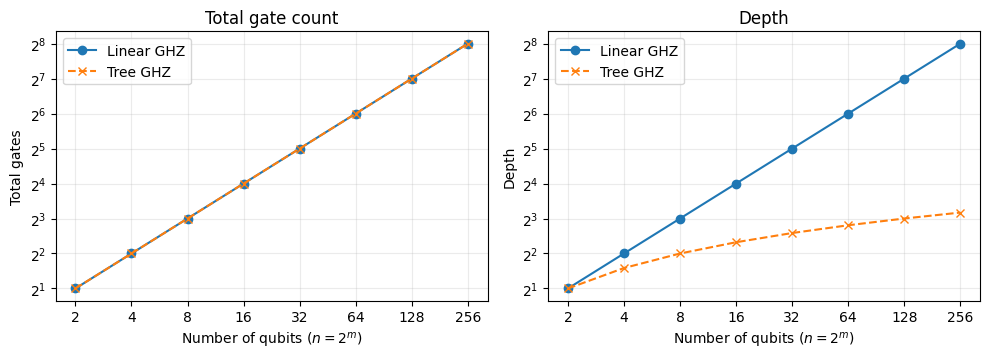

In [7]:
m_values = list(range(1, 9))
n_values = [2**m_value for m_value in m_values]

linear_resources_list = [linear_symbolic.evaluate(n=n) for n in n_values]
tree_resources_list = [
    tree_symbolic.evaluate(m=m, n=n) for m, n in zip(m_values, n_values, strict=True)
]
tree_specialized = [
    resources.logical(qm.specialize(tree_ghz, m=m, n=n))
    for m, n in zip(m_values, n_values, strict=True)
]

linear_gate_counts = [
    study.metric(resources.LOGICAL_GATES).numeric_enclosure()
    for study in linear_resources_list
]
tree_gate_counts = [
    study.metric(resources.LOGICAL_GATES).numeric_enclosure()
    for study in tree_resources_list
]
linear_gate_depths = [
    study.metric(resources.LOGICAL_GATE_DEPTH).numeric_enclosure()
    for study in linear_resources_list
]
tree_gate_depths = [
    study.metric(resources.LOGICAL_GATE_DEPTH).numeric_enclosure()
    for study in tree_specialized
]

for n, linear_study, tree_study in zip(
    n_values, linear_resources_list, tree_resources_list, strict=True
):
    assert linear_study.metric(peak_qubits).numeric_enclosure() == (n, n)
    assert tree_study.metric(peak_qubits).numeric_enclosure() == (n, n)
assert linear_gate_counts == tree_gate_counts == [(n, n) for n in n_values]
assert linear_gate_depths == [(n, n) for n in n_values]
assert tree_gate_depths == [(m + 1, m + 1) for m in m_values]

# 左側にゲート数をプロットします。
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for values, label, marker, linestyle in [
    (linear_gate_counts, "Linear GHZ", "o", "-"),
    (tree_gate_counts, "Tree GHZ", "x", "--"),
]:
    axes[0].plot(
        n_values,
        [lower for lower, _ in values],
        marker=marker,
        linestyle=linestyle,
        label=label,
    )
# 右側に回路の深さをプロットします。
for values, label, marker, linestyle in [
    (linear_gate_depths, "Linear GHZ", "o", "-"),
    (tree_gate_depths, "Tree GHZ", "x", "--"),
]:
    axes[1].plot(
        n_values,
        [lower for lower, _ in values],
        marker=marker,
        linestyle=linestyle,
        label=label,
    )
# 軸のラベルとグラフのタイトルを設定します。
axes[0].set(
    xlabel=r"Number of qubits ($n=2^m$)",
    ylabel="Total gates",
    title="Total gate count",
)
axes[1].set(
    xlabel=r"Number of qubits ($n=2^m$)",
    ylabel="Depth",
    title="Depth",
)
# 軸の目盛り、グリッド、凡例を設定します。
for axis in axes:
    axis.set_xscale("log", base=2)
    axis.set_yscale("log", base=2)
    axis.set_xticks(n_values)
    axis.set_xticklabels([str(value) for value in n_values])
    axis.grid(alpha=0.25)
    axis.legend()
# グラフを表示します。
plt.tight_layout()
plt.show()

総ゲート数は等しいため、曲線は重なります。一方、深さは鎖状の実装では$n$、もう一方の実装では$\log_2 n+1$です。そのため、量子ビット数が増えるほど差が広がります。[Cruzら](https://doi.org/10.1002/qute.201900015)

## 3. 固定コストのオラクルを含むQamomile qkernelのリソースを推定する

ここでは、オラクルを使ってリソースを推定します。Qamomileでは、本文が`...`のqkernelは実装を持たない演算を宣言します。これにより、問題固有の演算や実装方法が複数あるサブルーチンなどをすべて実装する前に、全体のリソースを推定できます。まず、`ResourceRule`でオラクルに固定コストを設定し、そのオラクルを使うQamomile qkernelのリソースを推定します。

In [8]:
@qm.qkernel(kind="unitary")
def fixed_state_preparation(q: qm.Q[qm.Bits[4]]) -> qm.Q[qm.Bits[4]]: ...


fixed_linear_ghz_cost = tuple(
    resources.ResourceRule(
        identity=f"hands-on.fixed-ghz.{metric.identifier}",
        callable=fixed_state_preparation,
        metric=metric,
        relation=resources.Relation.EQUALITY,
        expression=resources.literal(cost),
        provenance="hands-on.linear-ghz-cost",
        scheduling_footprint=(
            resources.SchedulingFootprint(("q",))
            if metric == resources.LOGICAL_GATE_DEPTH
            else None
        ),
    )
    for metric, cost in (
        (resources.LOGICAL_GATES, 4),
        (resources.LOGICAL_SINGLE_QUBIT_GATES, 1),
        (resources.LOGICAL_TWO_QUBIT_GATES, 3),
        (resources.LOGICAL_GATE_DEPTH, 4),
    )
)

In [9]:
@qm.qkernel
def fixed_cost_algorithm(theta: qm.Param[qm.Real]) -> qm.Shot[qm.Bits[4]]:
    """Apply a fixed-cost state-preparation oracle followed by an RZ gate."""
    q = qm.qubits(4)
    q = fixed_state_preparation(q)
    q = qm.rz(q, theta, target=3)
    return qm.measure(q)

In [10]:
fixed_resources = resources.logical(fixed_cost_algorithm, rules=fixed_linear_ghz_cost)
fixed_calls = resources.algorithmic_call_count(fixed_state_preparation.symbol)

print("=== Resource required ===")
print("#qubits:", fixed_resources.metric(peak_qubits).expression)
for label, metric in ghz_metrics.items():
    print(f"{label}: {fixed_resources.metric(metric)}")
print(f"#measurements: {fixed_resources.metric(resources.LOGICAL_MEASUREMENTS)}")
print(f"Oracle calls: {fixed_resources.metric(fixed_calls)}")

assert fixed_resources.metric(resources.LOGICAL_GATES).numeric_enclosure() == (5, 5)
assert fixed_resources.metric(resources.LOGICAL_MEASUREMENTS).numeric_enclosure() == (
    4,
    4,
)

=== Resource required ===
#qubits: 4
#single-qubit gates: = 2 semantic_operations
#two-qubit gates: = 3 semantic_operations
#total gates: = 5 semantic_operations
gate depth: = 5 dependency_steps
#measurements: = 4 measurements
Oracle calls: = 1 calls


このリソース推定には、オラクルに割り当てた固定コストが含まれます。オラクルには実装がないため、推定結果は指定したルールに依存します。深さのルールでは、オラクルが4つの量子ビットすべてを4ゲート層の間使うと定めています。RZゲートはそのうち1つの量子ビットに作用し、それらの層の後に実行されます。

## 4. 入力に依存するコストをルールで指定する

前の例では、オラクルに固定コストを設定しました。ここで扱う状態準備のように、オラクルのコストを入力の規模に応じて変えたい場合もあります。Qamomileでは、`ResourceRule`に記号式を渡すことで、このようなコストを指定できます。`rule_parameter`を使うと、式の中で入力の量子ビット数`n`を参照できます。以下では、入力に応じてコストが変わるオラクルを定義し、それを含むQamomile qkernelのリソースを推定します。

In [11]:
@qm.qkernel(kind="unitary")
def parameterized_state_preparation(
    q: qm.Q[qm.Bits[n]],  # noqa: F821
    n: qm.Int,
) -> qm.Q[qm.Bits[n]]: ...  # noqa: F821


oracle_width = resources.rule_parameter(
    parameterized_state_preparation,
    "n",
    domain=resources.Domain.NATURAL,
    constraints=("n >= 1",),
)
parameterized_linear_ghz_cost = tuple(
    resources.ResourceRule(
        identity=f"hands-on.parameterized-ghz.{metric.identifier}",
        callable=parameterized_state_preparation,
        metric=metric,
        relation=resources.Relation.EQUALITY,
        expression=cost,
        provenance="hands-on.linear-ghz-cost",
        scheduling_footprint=(
            resources.SchedulingFootprint(("q",))
            if metric == resources.LOGICAL_GATE_DEPTH
            else None
        ),
    )
    for metric, cost in (
        (resources.LOGICAL_GATES, oracle_width),
        (resources.LOGICAL_SINGLE_QUBIT_GATES, resources.literal(1)),
        (resources.LOGICAL_GATE_DEPTH, oracle_width),
    )
)

In [12]:
@qm.qkernel
def parameterized_algorithm(
    n: qm.Const[qm.Int], theta: qm.Param[qm.Real]
) -> qm.Shot[qm.Bits[n]]:  # noqa: F821
    """Estimate an algorithm with an input-dependent state-preparation cost."""
    q = qm.qubits(n)
    q = parameterized_state_preparation(q, n)
    q = qm.rz(q, theta, target=n - 1)
    return qm.measure(q)

In [13]:
parameterized_resources = resources.logical(
    parameterized_algorithm, rules=parameterized_linear_ghz_cost
)
parameterized_calls = resources.algorithmic_call_count(
    parameterized_state_preparation.symbol
)

print("=== Resource required ===")
print("#qubits:", oracle_width)
for label, metric in ghz_metrics.items():
    print(f"{label}: {parameterized_resources.metric(metric)}")
print(f"Oracle calls: {parameterized_resources.metric(parameterized_calls)}")

for width in (4, 8):
    estimate = parameterized_resources.evaluate(n=width)
    assert estimate.metric(peak_qubits).numeric_enclosure() == (width, width)
    assert estimate.metric(resources.LOGICAL_GATES).numeric_enclosure() == (
        width + 1,
        width + 1,
    )
    assert estimate.metric(parameterized_calls).numeric_enclosure() == (1, 1)

=== Resource required ===
#qubits: n
#single-qubit gates: = 2 semantic_operations
#two-qubit gates: in [0, n] semantic_operations
#total gates: = n + 1 semantic_operations
gate depth: = maximum(maximum(n + 1, maximum(n, 0)), maximum(n, n + 1)) dependency_steps
Oracle calls: = 1 calls


このモデルでは、オラクルに渡した$n$個の量子ビットを使います。
このリソース推定には、オラクルに割り当てた、入力の量子ビット数$n$に依存するコストが含まれます。固定コストの例と同様に、RZゲートはオラクルが使用した量子ビットに、オラクルの後で適用されます。ここでは、総ゲート数、1量子ビットゲート数、深さのルールを指定します。解析結果には、2量子ビットゲート数の上下限が示されます。

## まとめ

Qamomile qkernelを`resources.logical`に渡し、具体的な入力値を指定せずにリソースを記号式で推定しました。次に、2通りの実装から得たゲート数の式に具体的な値を代入し、木構造のQamomile qkernelを特殊化して正確なゲート深さを求めました。最後に、オラクルに固定コストと入力に依存するコストを定義しました。オラクルを使うQamomile qkernelのリソースを調べ、指定したコストが推定結果に反映されることを確認しました。